# Setup

In [1]:
import numpy as np
import qiskit 
import qiskit_aer

from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import HGate, XGate, SGate, SdgGate
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.result import marginal_counts
from qiskit.visualization import plot_histogram

In [2]:
print(qiskit.__version__)
print(qiskit_aer.__version__)

2.2.3
0.17.2


In [3]:
# Magic numbers
OPT_LEVEL = 0
SHOTS = 4096
SEED = 7
LAM1, LAM2 = 0.005, 0.02
P = 0.03

# default collections
NOISE = ("ideal", "gates", "readout", "combined")
BASIS_1Q = ['h','x','z','s','sdg','ry','rz','id']
BASIS_2Q = ['cx']
BASIS = BASIS_1Q + BASIS_2Q

In [4]:
# helper functions
def add_noise(kind: str):
    # add noise to the AerSimulator
    nm = NoiseModel()
    if kind in ("gates", "combined"):
        nm.add_all_qubit_quantum_error(depolarizing_error(LAM1, 1), BASIS_1Q)
        nm.add_all_qubit_quantum_error(depolarizing_error(LAM2, 2), BASIS_2Q)
    if kind in ("readout", "combined"):
        nm.add_all_qubit_readout_error(ReadoutError([[1 - P, P],[P, 1 - P]]))
    return nm

def run(q: QuantumCircuit, 
        noise: str, 
        shots: int = SHOTS, 
        seed: int = SEED, 
        opt_level: int = OPT_LEVEL):
    # run the thing
    sim = AerSimulator(method="density_matrix",
                       noise_model= add_noise(noise),
                       basis_gates=BASIS)
    tqc = transpile(q, sim, optimization_level=opt_level, seed_transpiler=seed)
    result = sim.run(tqc, shots=shots, seed_simulator=seed).result()
    return result, tqc

def print_table(results, title, dec=3, gap=3):
    cols = list(next(iter(results.values())).keys())
    labw = max(len(str(label)) for label in results) + gap
    colw = {c: max(len(str(c)), max(len(f"{row[c]:.{dec}f}") for row in results.values())) + gap
            for c in cols}

    print(title)
    print(f"{'':<{labw}}" + "".join(f"{str(c):>{colw[c]}}" for c in cols))
    for label, row in results.items():
        print(f"{str(label):<{labw}}" + "".join(f"{row[c]:>{colw[c]}.{dec}f}" for c in cols))
    print()

# Part A: Quantum Teleportation

In [5]:
PROBES = {
    "0": [],
    "1": [XGate()],
    "+": [HGate()],
    "-": [XGate(), HGate()],
    "+i": [HGate(), SGate()],
    "-i": [HGate(), SdgGate()]
}

# get the preparation and inverse-preparation stuff
def get_prep_circuits(probe):
    prep = QuantumCircuit(1, name="prep")
    for gate in PROBES[probe]:
        prep.append(gate, [0])
    post = prep.inverse()
    post.name = "post"
    return prep, post

def entangle():
    e = QuantumCircuit(2, name="entangle")
    e.h(0)
    e.cx(0, 1)
    return e

def quantum_teleportation(probe, bob_corrects=True):
    # q0 = unknown state, q1 = alice qubit, q2 = bob qubit
    # bob_corrects is whether bob will correct his qubit
    q = QuantumCircuit(3, 3)

    # prepare qubit
    prep, post = get_prep_circuits(probe)
    q.append(prep, [0])
    q.barrier()

    # alice and bob share e-pair
    q.append(entangle(), [1, 2])
    q.barrier()
    
    # start quantum tele
    q.cx(0, 1)

    # alice measure
    # q0 -> c0 and q1 -> c1
    q.h(0)
    q.measure(0, 0)
    q.measure(1, 1)

    # bob corrects
    if bob_corrects:
        with q.if_test((q.clbits[1], 1)):
            q.x(2)
        with q.if_test((q.clbits[0], 1)):
            q.z(2)
    q.barrier()

    # post-processing + measure
    # q2 -> c2, success if c2 = 0
    q.append(post, [2])
    q.measure(2, 2)
    return q

## Circuit
Using an arbitrary 0 starting state and assuming Bob corrects as usual:
- `prep` prepares the probe
- `post` post-processes Bob's qubit (with the inverse preparation operation)

In [6]:
quantum_teleportation("0").draw()

┌──────┐ ░               ░      ┌───┐┌─┐                          »
q_0: ┤ prep ├─░───────────────░───■──┤ H ├┤M├──────────────────────────»
     └──────┘ ░ ┌───────────┐ ░ ┌─┴─┐└┬─┬┘└╥┘                          »
q_1: ─────────░─┤0          ├─░─┤ X ├─┤M├──╫───────────────────────────»
              ░ │  entangle │ ░ └───┘ └╥┘  ║   ┌──────  ┌───┐ ───────┐ »
q_2: ─────────░─┤1          ├─░────────╫───╫───┤ If-0  ─┤ X ├  End-0 ├─»
              ░ └───────────┘ ░        ║   ║   └──╥───  └───┘ ───────┘ »
                                       ║   ║ ┌────╨────┐               »
c: 3/══════════════════════════════════╩═══╩═╡ c_1=0x1 ╞═══════════════»
                                       1   0 └─────────┘               »
«                                ░            
«q_0: ───────────────────────────░────────────
«                                ░            
«q_1: ───────────────────────────░────────────
«       ┌──────  ┌───┐ ───────┐  ░ ┌──────┐┌─┐
«q_2: ──┤ If-0  ─┤ Z ├  End-0 ├──░─┤ post ├┤M├
«       └──╥───  └───┘ ───────┘  ░ └──────┘└╥┘
«     ┌────╨────┐                           ║ 
«c: 3/╡ c_0=0x1 ╞═══════════════════════════╩═
«     └─────────┘                           2

In [7]:
prep, post = get_prep_circuits("+i")
print(prep.draw())
print(post.draw())

   ┌───┐┌───┐
q: ┤ H ├┤ S ├
   └───┘└───┘
   ┌─────┐┌───┐
q: ┤ Sdg ├┤ H ├
   └─────┘└───┘


In [8]:
entangle().draw()

┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

## Success Probabilities with Graph
Over all noise configs and probes,
* Probes that require more preparation have the lowest success probabilities. +-i has the worst under any noise due to it requiring the most gates
* P(success) decreases as more noise is added P_success(gates) and P_success(readout) > P_success(combined)

For Bob's correction,
* If Bob corrects, P(success) is decently high
* If Bob does not, P(success) is basically 50/50

In [9]:
resA = {}
for noise in NOISE:
    resA[noise] = {}
    for probe in PROBES:
        c = run(quantum_teleportation(probe, True), noise)[0].get_counts()
        resA[noise][probe] = marginal_counts(c, [2]).get("0", 0) / SHOTS
print_table(resA, "Success Probability P(c2=0), Bob corrects")

Success Probability P(c2=0), Bob corrects
                  0       1       +       -      +i      -i
ideal         1.000   1.000   1.000   1.000   1.000   1.000
gates         0.977   0.972   0.965   0.959   0.959   0.959
readout       0.941   0.941   0.937   0.937   0.910   0.910
combined      0.922   0.917   0.909   0.905   0.880   0.880



In [10]:
resA_nc = {"ideal, no corr.": {}}
for probe in PROBES:
    c = run(quantum_teleportation(probe, False), "ideal")[0].get_counts()
    resA_nc["ideal, no corr."][probe] = marginal_counts(c, [2]).get("0", 0) / SHOTS
print_table(resA_nc, "Success Probability P(c2=0), 'ideal' noise, no correction")

Success Probability P(c2=0), 'ideal' noise, no correction
                         0       1       +       -      +i      -i
ideal, no corr.      0.501   0.501   0.501   0.501   0.501   0.501



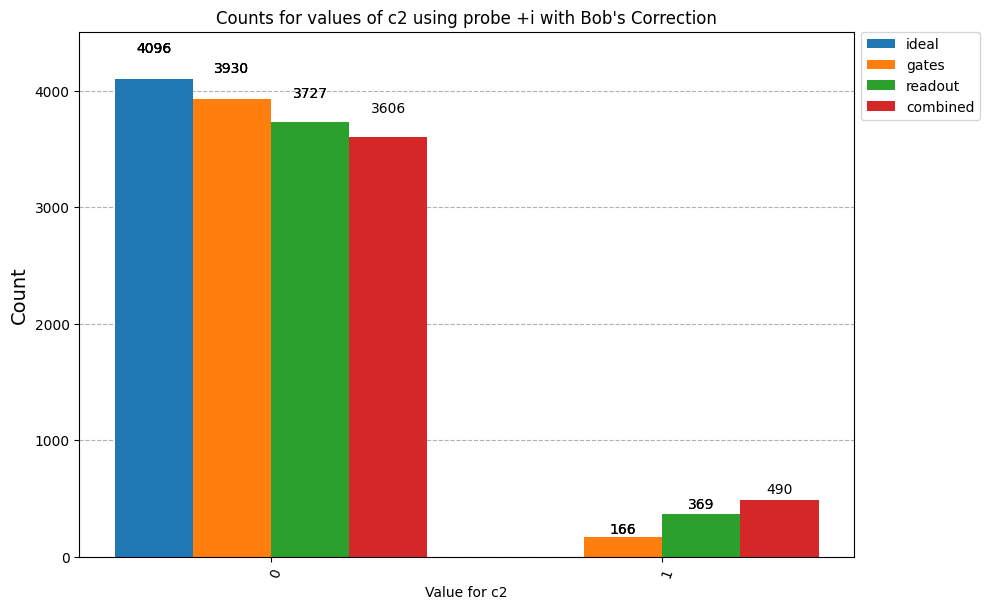

In [11]:
# plot histogram for +i probe with Bob correction, over all noise configs
fig = plot_histogram(
    [marginal_counts(run(quantum_teleportation("+i"), n)[0].get_counts(), [2]) for n in NOISE],
    legend=list(NOISE),
    title="Counts for values of c2 using probe +i with Bob's Correction",
    figsize=(10, 6))
fig.axes[0].set_xlabel("Value for c2")
fig

## Questions
* Why the phase-sensitive probes are useful: To prove the generalisability of the teleportation to multiple bases (X, Y and Z), the probes must be phase-sensitive to show that the teleportation (in the noiseless case) not only corrects for bits, but also phase as well. Additionally, simply using ket(0) or ket(1) cannot detect a missing correction for phase (Z), and ket(+) or ket(-) cannot detect a missing correction for bits (X), but ket(+i) and ket(-i) can detect for both.

* Why Bob needs Alice’s outcomes: Bob's qubit is maximally mixed, so regardless of which what measurement Alice applies to her part of the entangled pair, Bob will have no idea how to correct unless Alice gives him her measurements.

* Why readout errors can affect corrections: Because Bob relies on Alice's readouts to correct, if the readout induces an error, it can cause Bob to correct his qubit wrongly. This may introduce a mismatch between the final state of Bob's qubit and the state of the original unknown qubit, meaning the teleportation fails.

# Part B: Superdense Coding

In [12]:
TWO_QUBITS = ["00", "01", "10", "11"]

def entangle():
    e = QuantumCircuit(2, name="entangle")
    e.h(0)
    e.cx(0, 1)
    return e

def superdense_coding(message):
    # q[0] = alice qubit, q[1] = bob qubit
    q = QuantumCircuit(2, 2)
    q.append(entangle(), [0, 1])
    q.barrier()

    # alice performs ops depending on the message
    if message[0] == "1":
        q.z(0)
    if message[1] == "1":
        q.x(0)

    # alice sends to bob
    q.barrier()

    # bob performs bell measurement
    # success if bob measurement = input message
    # q0 -> c1, q1 -> c0
    q.cx(0, 1)
    q.h(0)
    q.measure(0, 1) # flip the order since q0 determines phase flip
    q.measure(1, 0)
    return q

## Circuit
From Bell state Phi+, if Alice wishes to encode "01" (i.e. bit flip only), she simply applies X to perform a bit-flip to Psi+. If she wishes to encode "10" instead, she will apply Z to perform a phase-flip from Phi+ to Phi-. If "11", then both Z and X will turn Phi+ into Psi-.

If Bob wishes to decode, he can simply perform a Bell measurement to map the Bell states into the 2-bit qubit basis state (ket(00), ket(01), ket(10), ket(11))

Assuming the message sent is "11" and entangled bit preparation is included

In [13]:
superdense_coding("11").draw()

┌───────────┐ ░ ┌───┐┌───┐ ░      ┌───┐┌─┐
q_0: ┤0          ├─░─┤ Z ├┤ X ├─░───■──┤ H ├┤M├
     │  entangle │ ░ └───┘└───┘ ░ ┌─┴─┐└┬─┬┘└╥┘
q_1: ┤1          ├─░────────────░─┤ X ├─┤M├──╫─
     └───────────┘ ░            ░ └───┘ └╥┘  ║ 
c: 2/════════════════════════════════════╩═══╩═
                                         0   1

In [14]:
entangle().draw()

┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘

## Success Probabilities with Graph
Across all noises and messages
* For "gates", P(success) decreases from "00" to "11" as Alice needs to use more gates to prepare her qubit (0 for "00", 1 for "01" and "10", 2 for "11"), meaning more noise on top of the Bell measurement gates (CNOT and H)
* For "readout", P(success) is roughly 0.97^2 since two measurements are done
* For "combined", P(success) is roughly P_success(gates) * P_success(readout) = 0.97^2 * 0.963 = 0.906 for "00", 0.899 for "01" and "10", and 0.898 for "11"

In [15]:
resB = {}
for noise in NOISE:
    resB[noise] = {}
    for message in TWO_QUBITS:
        c = run(superdense_coding(message), noise)[0].get_counts()
        resB[noise][message] = c.get(message, 0) / SHOTS
print_table(resB, "Success Probability across input messages")

Success Probability across input messages
                 00      01      10      11
ideal         1.000   1.000   1.000   1.000
gates         0.963   0.956   0.959   0.955
readout       0.942   0.940   0.946   0.944
combined      0.906   0.898   0.907   0.904



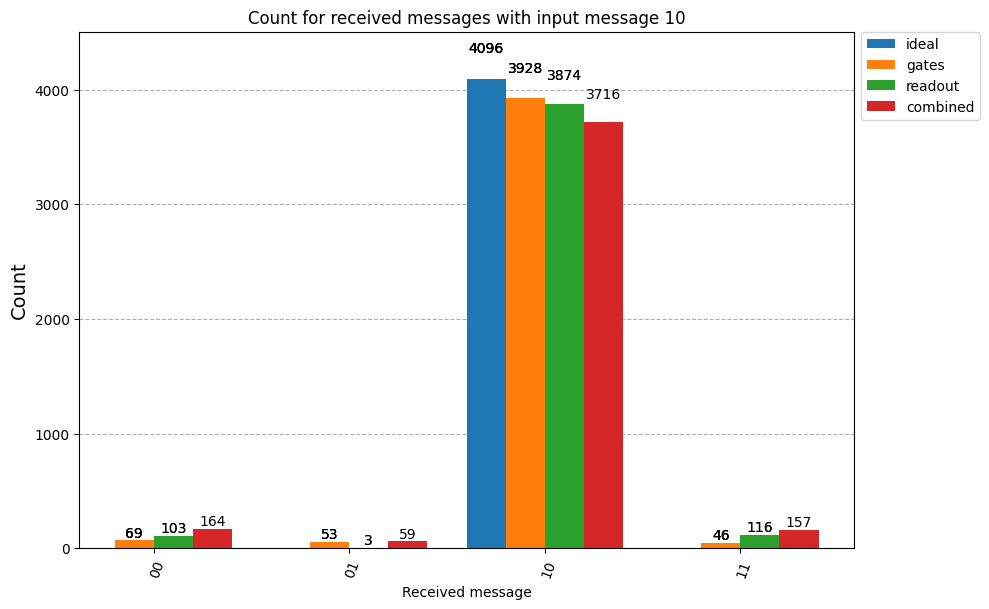

In [16]:
fig = plot_histogram(
    [run(superdense_coding("10"), n)[0].get_counts() for n in NOISE],
    legend=list(NOISE),
    title="Count for received messages with input message 10",
    figsize=(10, 6)
)
fig.axes[0].set_xlabel("Received message")
fig

## Repeating `readout`
* Std is tighter for higher number of shots, but converges to roughly the same average across seeds

In [17]:
_message = "10"
_noise = "readout"
_shots = [256, 8192]
_seeds = [7, 8, 9]

resB_shots = {}
for shots in _shots:
    for seed in _seeds:
        c = run(superdense_coding(_message), _noise, shots, seed)[0].get_counts()
        p = c.get("10", 0) / shots
        resB_shots[f"{shots} shots, seed {seed}"] = {"p_hat": p, "std err": np.sqrt(p * (1 - p) / shots)}

# theoretical value here
resB_shots["theoretical value"] = {"p_hat": (1-P)**2, "std err": 0.0}
print_table(resB_shots, "Success Probabilities and Std Errors under readout noise", dec=4)

Success Probabilities and Std Errors under readout noise
                         p_hat   std err
256 shots, seed 7       0.9297    0.0160
256 shots, seed 8       0.9102    0.0179
256 shots, seed 9       0.9414    0.0147
8192 shots, seed 7      0.9427    0.0026
8192 shots, seed 8      0.9420    0.0026
8192 shots, seed 9      0.9437    0.0025
theoretical value       0.9409    0.0000



## Questions
* Why more shots do not remove the readout error: The readout error is independent of the number of shots, and the recorded P(success) in this case should approach P = (1 - r)^2 = 0.97^2 = 0.9409 since two classical bits are read on Bob's side

* Why we still need a preshared Bell pair + 1 qubit transmission: The Bell pair enables 4 possible orthogonal Bell states compared to a single qubit (which by the Holevo bound only can store 1 bit of information), and the 1 qubit transmission needs to happen because Bob's qubit is still maximally mixed even despite Alice's operations, meaning the information is encoded in their entanglement and Bob needs both qubits to decode any useful information.

# Part C: Deutsch–Jozsa

In [18]:
ORACLE_KINDS = ["f=0", "f=1", "f=x0", "f=x1XORx0"]

def oracle_dj(oracle_kind):
    o = QuantumCircuit(3, name="oracle")

    # if f = 0, do nothing since y XOR 0 = y
    if oracle_kind == "f=0":
        pass

    # if f = 1, always flip q2 since y XOR 1 = NOT y
    elif oracle_kind == "f=1":
        o.x(2)

    # if f = x0, flip q2 if q0 = 1, else do nothing (equiv CNOT)
    elif oracle_kind == "f=x0":
        o.cx(0, 2)

    # if f = x1 XOR x0, y XOR x1 XOR x0 is equivalent to x0 XOR (x1 XOR y)
    # so y is flipped once if either x0 or x1 is 1 but not both
    # y flipped twice if both are 1
    elif oracle_kind == "f=x1XORx0":
        o.cx(0, 2)
        o.cx(1, 2)

    return o

def deutsch_jozsa(oracle_kind):
    # q[0, 1] are input qubits, q2 is answer qubit
    q = QuantumCircuit(3, 2)

    # prepare 2nd qubit to ket(-)
    q.x(2)
    q.h(2)
    q.barrier()

    # place q0 and q1 in superposition
    q.h([0, 1])

    # ask oracle
    q.append(oracle_dj(oracle_kind), [0, 1, 2])

    # measure q0 -> c0 and q1 -> c1
    q.h([0, 1])
    q.measure(0, 0)
    q.measure(1, 1)
    return q

## Circuit

In [19]:
deutsch_jozsa("f=0").draw()

░ ┌───┐┌─────────┐┌───┐┌─┐   
q_0: ───────────░─┤ H ├┤0        ├┤ H ├┤M├───
                ░ ├───┤│         │├───┤└╥┘┌─┐
q_1: ───────────░─┤ H ├┤1 oracle ├┤ H ├─╫─┤M├
     ┌───┐┌───┐ ░ └───┘│         │└───┘ ║ └╥┘
q_2: ┤ X ├┤ H ├─░──────┤2        ├──────╫──╫─
     └───┘└───┘ ░      └─────────┘      ║  ║ 
c: 2/═══════════════════════════════════╩══╩═
                                        0  1

In [20]:
oracle_dj("f=x1XORx0").draw()

q_0: ──■───────
       │       
q_1: ──┼────■──
     ┌─┴─┐┌─┴─┐
q_2: ┤ X ├┤ X ├
     └───┘└───┘

## Success Probabilities and Graph
* Again, P(success) decrease as the errors increase in severity: P_success(gates) and P_success(readout) > P_success(combined)

In [21]:
print("Ideal output strings (c1,c0)")
for kind in ORACLE_KINDS:
    print(f"  {kind:<12}", run(deutsch_jozsa(kind), "ideal")[0].get_counts())
print()

Ideal output strings (c1,c0)
  f=0          {'00': 4096}
  f=1          {'00': 4096}
  f=x0         {'01': 4096}
  f=x1XORx0    {'11': 4096}



In [22]:
resC = {}
for noise in NOISE:
    resC[noise] = {}
    for kind in ORACLE_KINDS:
        c = run(deutsch_jozsa(kind), noise)[0].get_counts()
        if kind in ("f=0", "f=1"):
            good = c.get("00", 0)
        else:
            good = sum(v for k, v in c.items() if k != "00")
        resC[noise][kind] = good / SHOTS
print_table(resC, "Success Probability of correct classification")

Success Probability of correct classification
                f=0     f=1    f=x0   f=x1XORx0
ideal         1.000   1.000   1.000       1.000
gates         0.990   0.990   0.979       0.988
readout       0.942   0.942   0.969       0.998
combined      0.933   0.933   0.950       0.985



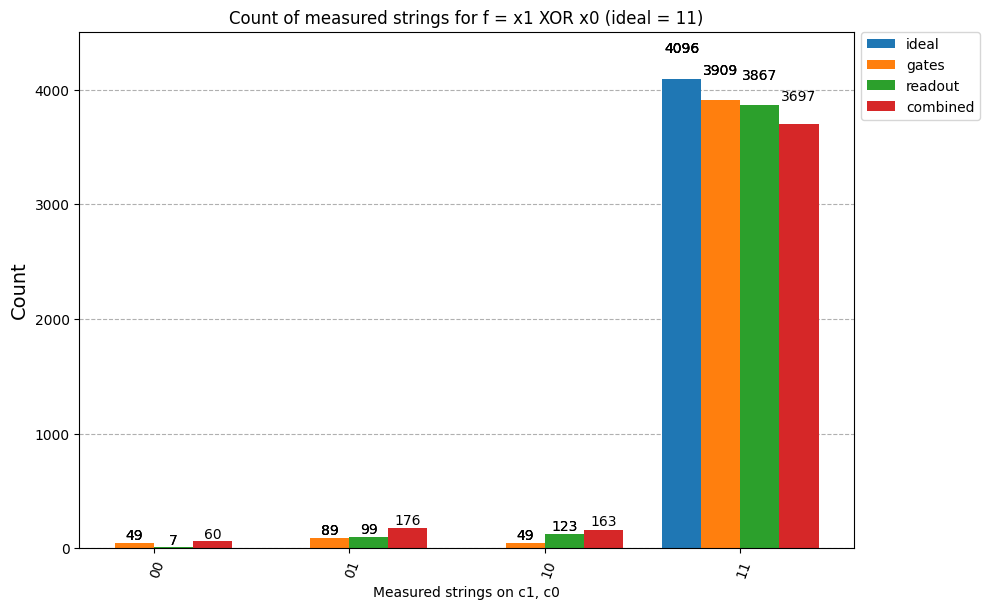

In [23]:
fig = plot_histogram(
    [run(deutsch_jozsa("f=x1XORx0"), n)[0].get_counts() for n in NOISE],
    legend=list(NOISE),
    title="Count of measured strings for f = x1 XOR x0 (ideal = 11)",
    figsize=(10, 6)
)
fig.axes[0].set_xlabel("Measured strings on c1, c0")
fig

## Questions
* Role of phase kickback: Because q0 and q1 are in the ket(+) state (due to the H gates at the start), if the function is balanced, then the CNOT on q2 depends on if f=x0 or f=x1 XOR x0. This means that for either case, q0 (and q1 for the latter case) will "pick up" the negative phase from q2 since ket(-) is an eigenstate of X and will flip the phase for the ket(1) in ket(+), transforming it to ket(-). This kickback is thus noticeable for balanced functions but not necessarily so for f=1.

* Role of the final H gates: Once the above kickback happens, the H gates will prepare q0 and q1 to be measured in the computational basis of Z. If the function is balanced, then at least one qubit in q0 or q1 will be ket(1), otherwise both will be ket(0).

* Why is a noisy nonzero outcome no longer a conclusive test: If noise is introduced, then it is possible for readout or gate errors to perturbate the results such that a balanced oracle function can appear to be constant and vice versa. One result is thus not enough to determine the nature of the oracle function.

# Part D: Grover Search

In [24]:
def oracle():
    # mark ket(10)
    # so ket(10) -> X(1) -> ket(11) -> CZ(0, 1) -> -ket(11)
    o = QuantumCircuit(2, name="oracle")
    o.x(1)
    o.cz(0, 1)
    o.x(1)
    return o

def diffuse():
    d = QuantumCircuit(2, name="diffuse")
    d.h([0, 1])
    d.x([0, 1])
    d.cz(0, 1)
    d.x([0, 1])
    d.h([0, 1])
    return d

def grover_search(itera=1, redundant=0):
    # assume ket(10) means q0 = ket(1), q1 = ket(0)
    q = QuantumCircuit(2, 2)
    q.h([0, 1])
    q.barrier()

    # add redundant CNOT pairs if need
    for _ in range(redundant):
        q.cx(0, 1)
        q.cx(0, 1)
    q.barrier()

    # grover iters
    for _ in range(itera):
        o = oracle()
        d = diffuse()
        q.append(o, [0, 1])
        q.append(d, [0, 1])
        q.barrier()

    # reverse the order due to the mapping
    q.measure(0, 1)
    q.measure(1, 0)
    return q

## Circuit
For a Grover Search with 1 pair of unnecessary gates and 1 iteration

In [25]:
grover_search(1, 1).draw()

┌───┐ ░            ░ ┌─────────┐┌──────────┐ ░ ┌─┐   
q_0: ┤ H ├─░───■────■───░─┤0        ├┤0         ├─░─┤M├───
     ├───┤ ░ ┌─┴─┐┌─┴─┐ ░ │  oracle ││  diffuse │ ░ └╥┘┌─┐
q_1: ┤ H ├─░─┤ X ├┤ X ├─░─┤1        ├┤1         ├─░──╫─┤M├
     └───┘ ░ └───┘└───┘ ░ └─────────┘└──────────┘ ░  ║ └╥┘
c: 2/════════════════════════════════════════════════╩══╩═
                                                     1  0

In [26]:
oracle().draw()

q_0: ──────■──────
     ┌───┐ │ ┌───┐
q_1: ┤ X ├─■─┤ X ├
     └───┘   └───┘

In [27]:
diffuse().draw()

┌───┐┌───┐   ┌───┐┌───┐
q_0: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     ├───┤├───┤ │ ├───┤├───┤
q_1: ┤ H ├┤ X ├─■─┤ X ├┤ H ├
     └───┘└───┘   └───┘└───┘

## Success Probabilities and Graph
* For all noise levels, P(success) starts at roughly 0.244 and increases to a maximum after 1 iteration (P = 1 for the ideal case, P < 1 for the rest depending on the noise), then goes back to 0.244 after the 2nd iteration

In [28]:
_iters = [0, 1, 2]

resD = {}
for noise in NOISE:
    resD[noise] = {}
    for iters in _iters:
        c = run(grover_search(iters), noise)[0].get_counts()
        resD[noise][iters] = c.get("10", 0) / SHOTS
print_table(resD, "Success Probability of obtaining 10 over Grover iterations")

Success Probability of obtaining 10 over Grover iterations
                  0       1       2
ideal         0.246   1.000   0.246
gates         0.246   0.917   0.246
readout       0.243   0.946   0.243
combined      0.243   0.869   0.243



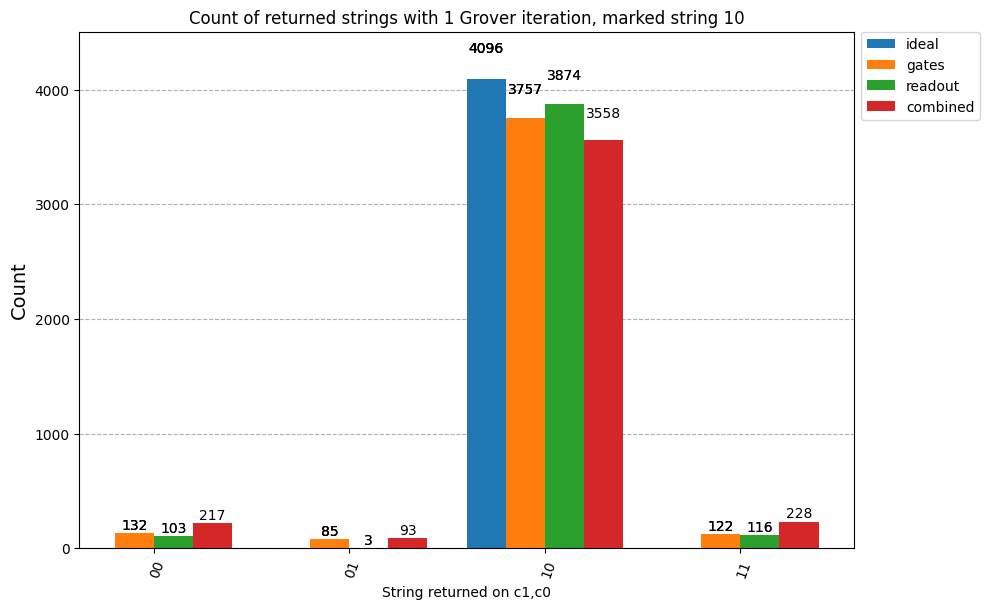

In [29]:
fig = plot_histogram(
    [run(grover_search(1), n)[0].get_counts() for n in NOISE],
    legend=list(NOISE),
    title="Count of returned strings with 1 Grover iteration, marked string 10",
    figsize=(10, 6)
)
fig.axes[0].set_xlabel("String returned on c1,c0")
fig

## Unnecessary Gates

In [30]:
_iters = 1
_redundants = [0, 5]
_noise = ["ideal", "combined"]

resD_red = {}
for noise in _noise:
    resD_red[noise] = {}
    for red in _redundants:
        result, tqc = run(grover_search(_iters, red), noise)
        cx = tqc.count_ops().get("cx", 0)
        resD_red[noise][f"{'orig' if red == 0 else '+5 pairs'} ({cx} CX)"] = result.get_counts().get("10", 0) / SHOTS
print_table(resD_red, "Success Probabilities for 1 Grover iteration over no. of redundant gates")

Success Probabilities for 1 Grover iteration over no. of redundant gates
              orig (2 CX)   +5 pairs (12 CX)
ideal               1.000              1.000
combined            0.869              0.762



## Questions:
* Role of phase oracle: It flips the sign of the marked state (ket(10) -> -ket(10)) and leaves the others alone.

* Role of diffusion: It reflects all amplitudes about the mean and essentially pushes the probability of the marked state up while reducing the rest, so after measurement the marked state has a higher probability of being measured.

* Why more iterations need not help: Because the probability amplitude of the marked state is maximal after 1 iteration, it could overshoot on the 2nd iteration.

* Why removing redundant pairs can improve success: The redundant gates have no effect on the correctness of the result, but introduce additional gate noise (from depolarization) which decreases the probability of success. This hints at the requirement for accurate, well-controlled gates. Every operation incurs some fidelity tradeoff, fewer gates and/or lower errors per gate are preferred over redundant gates or high errors for an algorithm.

* Is this QEC: No, removing gates is not QEC because no error is actively being corrected in terms of bit-flips or phase-flips. QEC measures error syndromes but this does not. Additionally, adding gates here does not improve error correction like QEC, it conversely worsens the error and noise.